# Finding the right features (works with any dataset)

This notebook walks through choosing which features to give a model. It works for any problem where we want to predict **one of two answers** (yes/no, sick/healthy, spam/not spam) from a table of numbers.

The steps:

1. Load the data and turn the answer into 0 and 1.
2. (Only if needed) turn many rows per person into one row per person.
3. Split the rows into three groups: training, practice and test.
4. **Step 1:** score each feature on its own with ROC AUC.
5. **Step 2:** use a heatmap to remove features that are copies of each other.
6. **Step 3:** check that a hidden factor (like age) isn't doing the work.
7. **Step 4:** train a model and keep only the features that help it.

Out of the box it uses a small example dataset built into scikit-learn (measurements of breast tissue samples, labelled cancerous or not). To use your own data, change the settings in the next cell.

## Settings

This is the only cell you need to change for a new dataset.

In [1]:
# ---- settings: change these for your own data ----
DATA_FILE = None          # path to a .csv or .parquet file. None uses scikit-learn's built-in example data
TARGET = "diagnosis"      # the column we want to predict. It must have exactly two different values
POSITIVE = "malignant"    # which of the two values counts as 1 ("yes"). None picks one automatically
GROUP = None              # if each person has many rows, the column that says who each row belongs to. None if one row per person
MIN_ROWS_PER_GROUP = 1000 # with GROUP: people with fewer rows than this are left out
HIDDEN_FACTOR = None      # optional column to check in step 3 (for example age). It is never used as a feature
COLUMNS = None            # optional list of columns to load, which saves memory on big files. None loads everything
SIMILARITY_LIMIT = 0.8    # two features more alike than this (on the heatmap) count as copies of each other

# Example: the Tappy keystroke data from the earlier lessons
# DATA_FILE = "data.parquet"
# TARGET = "parkinsons"
# POSITIVE = True
# GROUP = "user_code"
# HIDDEN_FACTOR = "birthyear"
# COLUMNS = ["user_code", "hold_time", "latency_time", "parkinsons", "birthyear"]

## 1. Load the data

The answer column is turned into numbers: **1** for the `POSITIVE` value and **0** for the other one, because scikit-learn's models and scores expect numbers. Rows with no answer are removed, since a model can't learn from them.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

if DATA_FILE is None:
    from sklearn.datasets import load_breast_cancer
    example = load_breast_cancer(as_frame=True)
    data = example.frame.rename(columns={"target": TARGET})
    data[TARGET] = data[TARGET].map({0: "malignant", 1: "benign"})
elif str(DATA_FILE).endswith(".parquet"):
    data = pd.read_parquet(DATA_FILE, columns=COLUMNS)
else:
    data = pd.read_csv(DATA_FILE, usecols=COLUMNS)

data = data.dropna(subset=[TARGET])

answers = list(data[TARGET].unique())
assert len(answers) == 2, f"{TARGET} must have exactly two different values, but it has {answers}"
positive = POSITIVE if POSITIVE is not None else sorted(answers, key=str)[-1]
data[TARGET] = (data[TARGET] == positive).astype(int)

print(len(data), "rows")
print(f"{TARGET} = 1 means {positive!r}; share of rows that are 1: {data[TARGET].mean():.2f}")
data.head()

569 rows
diagnosis = 1 means 'malignant'; share of rows that are 1: 0.37


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. One row per person (only if `GROUP` is set)

Sometimes every person has many rows, like one row per key press in the Tappy data. A single row says little about a person, so we describe each person with a few summary numbers instead. For every number column we work out:

- the **median** (the middle value: half of that person's values are below it, half above), and
- the **spread** (how far apart the middle half of their values are: the 75% value minus the 25% value). A small spread means the person is consistent.

People with fewer than `MIN_ROWS_PER_GROUP` rows are left out, because a few rows aren't enough to describe someone. If `GROUP` is `None`, the data is already one row per person and this step does nothing.

In [3]:
if GROUP is not None:
    number_columns = [c for c in data.select_dtypes("number").columns if c not in (TARGET, HIDDEN_FACTOR)]
    grouped = data.groupby(GROUP)
    table = pd.DataFrame({"rows": grouped.size()})
    for column in number_columns:
        quartiles = grouped[column].quantile([0.25, 0.5, 0.75]).unstack()
        table[f"{column}_median"] = quartiles[0.5]
        table[f"{column}_spread"] = quartiles[0.75] - quartiles[0.25]
    table[TARGET] = grouped[TARGET].first()
    if HIDDEN_FACTOR is not None:
        table[HIDDEN_FACTOR] = grouped[HIDDEN_FACTOR].first()
    table = table[table["rows"] >= MIN_ROWS_PER_GROUP].drop(columns="rows")
    del data, grouped   # the raw rows aren't needed any more, so free the memory
else:
    table = data

# features = every number column except the answer and the hidden factor
features = [c for c in table.select_dtypes("number").columns if c not in (TARGET, HIDDEN_FACTOR)]
features = [c for c in features if table[c].nunique() > 1]   # a column that never changes can't help

rows_before = len(table)
table = table.dropna(subset=features)
print(len(table), "rows (people)", f"({rows_before - len(table)} removed for missing values)")
print(len(features), "features:", features)

569 rows (people) (0 removed for missing values)
30 features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


## 3. Split into training, practice and test groups

We split the rows three ways:

| Group | Share | Used for |
|---|---|---|
| **Training** | 60% | Learning: scoring features and training models |
| **Practice** | 20% | Making choices: checking whether removing a feature helps |
| **Test** | 20% | The final score, used **once** at the very end |

Why three? Every time we use a group to make a choice, its score stops being a fair measure, because we picked whatever looked best on it. Keeping the test group untouched until the end means its score is honest.

`stratify` makes each group have the same share of 1s and 0s as the full data.

In [4]:
from sklearn.model_selection import train_test_split

rest, test = train_test_split(table, test_size=0.2, stratify=table[TARGET], random_state=42)
train, practice = train_test_split(rest, test_size=0.25, stratify=rest[TARGET], random_state=42)
print(len(train), "training,", len(practice), "practice,", len(test), "test")

# for comparison later: the accuracy of always guessing the more common answer
majority = max(test[TARGET].mean(), 1 - test[TARGET].mean())
print(f"always guessing the more common answer would be right {majority:.0%} of the time on the test group")

341 training, 114 practice, 114 test
always guessing the more common answer would be right 63% of the time on the test group


## Step 1: Score each feature on its own

We treat each feature as if it were a model's score and work out its ROC AUC against the answer, using the training group only.

- **Strength** is how far the AUC is from 0.5: 0.80 and 0.20 are equally strong.
- **Above 0.5:** higher values of the feature point towards 1.
- **Below 0.5:** *lower* values point towards 1. The feature is still useful, it just works in reverse.

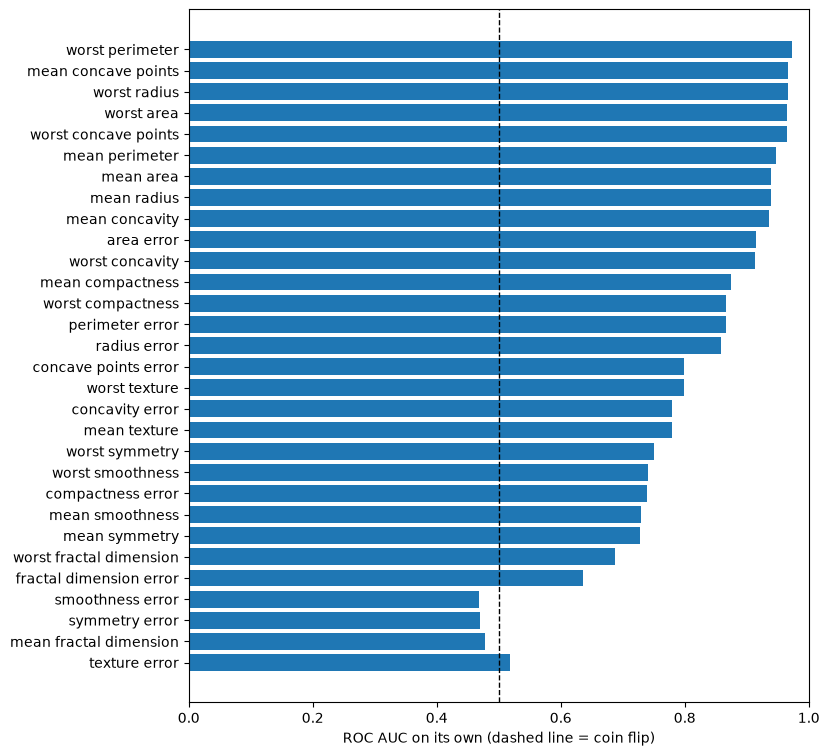

,feature,auc,strength
0,worst perimeter,0.972,0.472
1,mean concave points,0.967,0.467
2,worst radius,0.967,0.467
3,worst area,0.965,0.465
4,worst concave points,0.965,0.465
5,mean perimeter,0.947,0.447
6,mean area,0.939,0.439
7,mean radius,0.939,0.439
8,mean concavity,0.936,0.436
9,area error,0.915,0.415


In [5]:
ranking = pd.DataFrame([
    {"feature": f, "auc": roc_auc_score(train[TARGET], train[f])} for f in features
])
ranking["strength"] = (ranking["auc"] - 0.5).abs()
ranking = ranking.sort_values("strength", ascending=False).reset_index(drop=True)

_, ax = plt.subplots(figsize=(8, max(3, 0.3 * len(ranking))))
ax.barh(ranking["feature"], ranking["auc"])
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)   # 0.5 = no better than a coin flip
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("ROC AUC on its own (dashed line = coin flip)")
plt.show()

ranking.round(3)

## Step 2: Remove features that are copies of each other

The heatmap shows how alike every pair of features is across the training rows:

- **+1 (dark red):** they go up and down together, so they carry the same information.
- **0 (white):** unrelated, so each tells us something different.
- **−1 (dark blue):** one goes up when the other goes down. That's also the same information, just flipped.

The diagonal is always 1 (every feature matches itself), and the two halves of the square are mirror images.

Then we go down the ranking from Step 1, strongest first, and keep a feature only if it isn't too alike (above `SIMILARITY_LIMIT`, either red or blue) to one we've already kept.

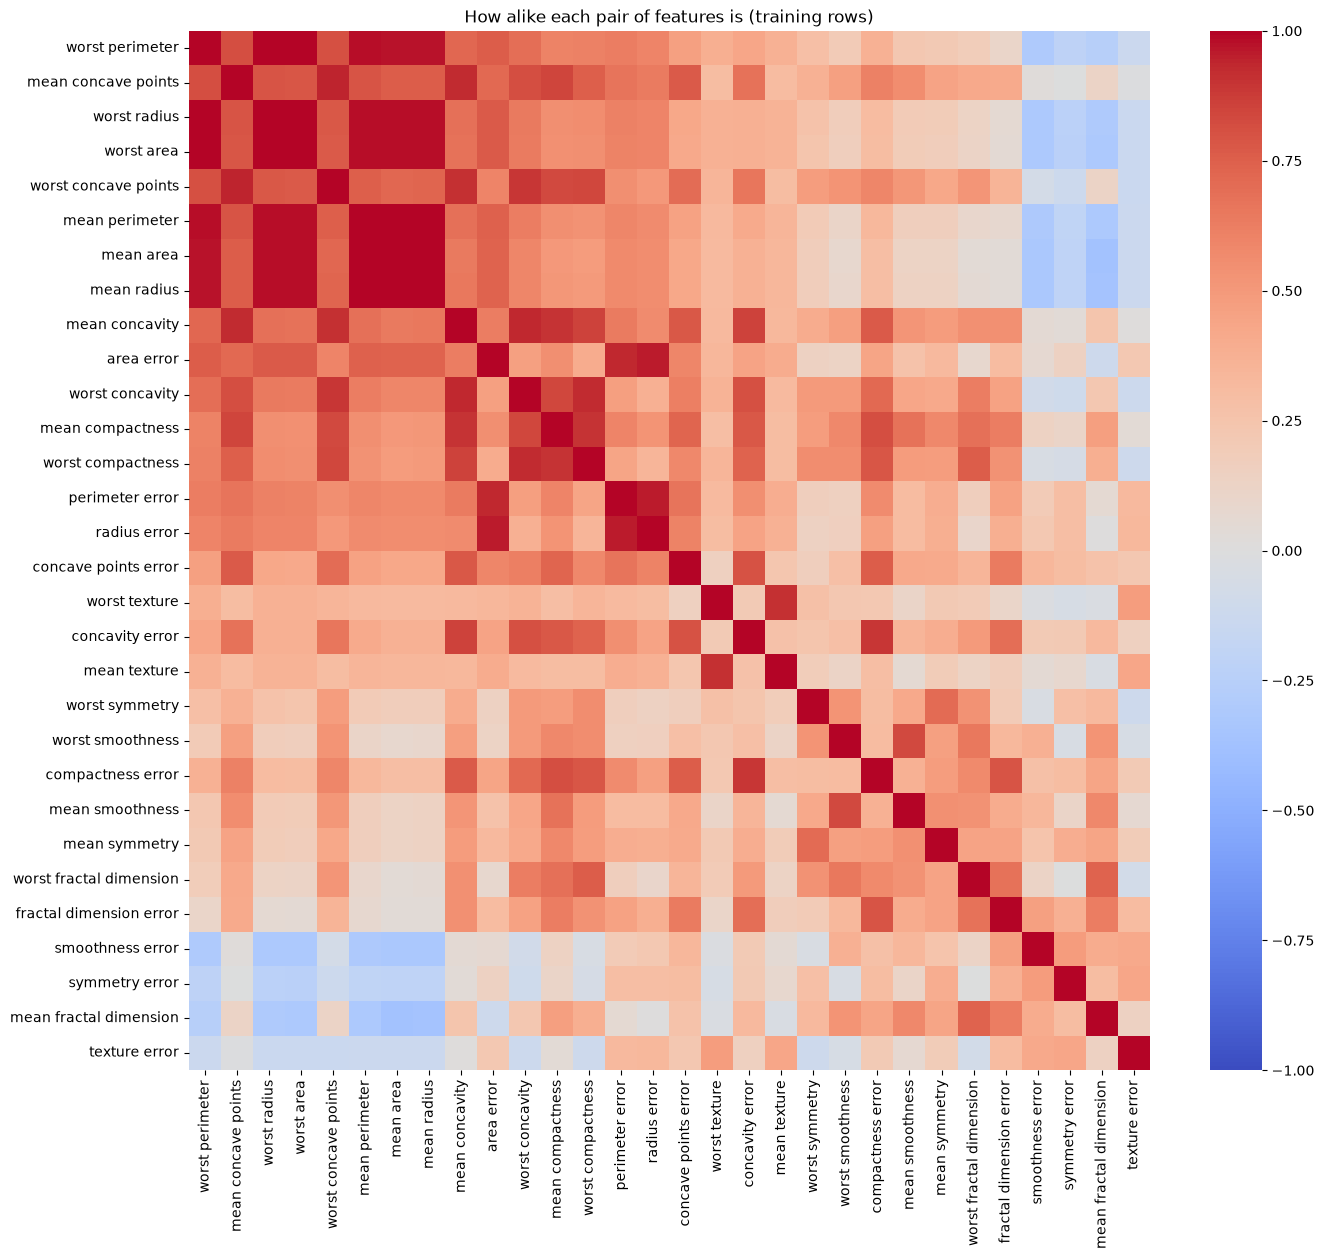

kept 15 of 30 features: ['worst perimeter', 'mean concavity', 'area error', 'concave points error', 'worst texture', 'worst symmetry', 'worst smoothness', 'compactness error', 'mean symmetry', 'worst fractal dimension', 'fractal dimension error', 'smoothness error', 'symmetry error', 'mean fractal dimension', 'texture error']


In [6]:
# "spearman" compares the order of values rather than the values themselves, so a few extreme values can't distort it
similarity = train[ranking["feature"]].corr(method="spearman")

size = max(6, 0.45 * len(features))
_, ax = plt.subplots(figsize=(size + 2, size))
sns.heatmap(similarity, annot=len(features) <= 15, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("How alike each pair of features is (training rows)")
plt.show()

selected = []
for feature in ranking["feature"]:
    if all(abs(similarity.loc[feature, kept]) < SIMILARITY_LIMIT for kept in selected):
        selected.append(feature)
print(f"kept {len(selected)} of {len(features)} features:", selected)

## Step 3: Check for a hidden factor (only if `HIDDEN_FACTOR` is set)

Sometimes a feature seems to predict the answer, but really it's following something else. For example, older people type more slowly. If the group with the disease were older, "slow typing" could look like a sign of the disease when it's really a sign of age.

The check:

1. Score the hidden factor on its own with ROC AUC. If it's close to 0.5, it can't tell the groups apart, so it can't be fooling the features.
2. Split the rows into the lower half and upper half of the hidden factor (for example older and younger) and score each kept feature inside each half. If a feature only worked because of the hidden factor, its AUC would fall towards 0.5 inside the halves.

In [7]:
if HIDDEN_FACTOR is None:
    print("No HIDDEN_FACTOR set, so this step is skipped.")
    hidden_check = None
else:
    known = train.dropna(subset=[HIDDEN_FACTOR])
    print(f"{HIDDEN_FACTOR} on its own, ROC AUC: {roc_auc_score(known[TARGET], known[HIDDEN_FACTOR]):.3f}")
    halves = pd.qcut(known[HIDDEN_FACTOR], 2, labels=[f"lower half of {HIDDEN_FACTOR}", f"upper half of {HIDDEN_FACTOR}"])
    hidden_check = pd.DataFrame({
        half: {f: roc_auc_score(part[TARGET], part[f]) for f in selected}
        for half, part in known.groupby(halves, observed=True)
    })
    hidden_check.insert(0, "all rows", ranking.set_index("feature").loc[selected, "auc"])
hidden_check.round(3) if hidden_check is not None else None

No HIDDEN_FACTOR set, so this step is skipped.


## Step 4: Keep only the features that help the model

Scoring features one at a time doesn't tell the whole story: a feature can be strong on its own but add nothing once a similar feature is already in the model. So we build the model up one feature at a time:

1. Start with the strongest kept feature from Step 2.
2. Try adding the next one, retrain, and score the model on the **practice** group.
3. Keep the new feature only if the practice ROC AUC goes up by at least `MIN_IMPROVEMENT`. Otherwise leave it out.
4. Repeat until every kept feature has been tried.

The minimum improvement stops us keeping features that only change the score by a tiny, lucky amount.

(Logistic regression multiplies each feature by a weight and adds them up. The `StandardScaler` puts all features on the same scale first, so no feature counts for more just because its numbers are bigger.)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def logistic_regression():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

def practice_auc(columns):
    model = logistic_regression().fit(train[columns], train[TARGET])
    return roc_auc_score(practice[TARGET], model.predict_proba(practice[columns])[:, 1])

MIN_IMPROVEMENT = 0.005

final_features = [selected[0]]
best_score = practice_auc(final_features)
history = [{"feature tried": selected[0], "practice AUC": best_score, "kept": True}]

for feature in selected[1:]:
    score = practice_auc(final_features + [feature])
    kept = score >= best_score + MIN_IMPROVEMENT
    history.append({"feature tried": feature, "practice AUC": score, "kept": kept})
    if kept:
        final_features.append(feature)
        best_score = score

print("final features:", final_features)
pd.DataFrame(history).round(3)

final features: ['worst perimeter', 'area error', 'worst symmetry']


,feature tried,practice AUC,kept
0,worst perimeter,0.979,True
1,mean concavity,0.980,False
2,area error,0.985,True
3,concave points error,0.983,False
4,worst texture,0.989,False
5,worst symmetry,0.991,True
6,worst smoothness,0.989,False
7,compactness error,0.991,False
8,mean symmetry,0.990,False
9,worst fractal dimension,0.992,False


## Final score on the test group

Now, and only now, we use the test group. The models are trained on the training and practice groups together (more data to learn from) and scored once on the test group. We compare:

- logistic regression with **every** feature,
- logistic regression with the **final** features, and
- a small decision tree with the final features.

Because no choice was made using the test group, these scores are a fair estimate of how the models would do on new data. We don't go back and change the features after seeing them; that would make the test group just another practice group.

In [9]:
from sklearn.tree import DecisionTreeClassifier

learn = pd.concat([train, practice])

def test_auc(model, columns):
    model.fit(learn[columns], learn[TARGET])
    return roc_auc_score(test[TARGET], model.predict_proba(test[columns])[:, 1])

results = pd.DataFrame([
    {"model": "logistic regression", "features": f"all {len(features)}",
     "test ROC AUC": test_auc(logistic_regression(), features)},
    {"model": "logistic regression", "features": f"final {len(final_features)}",
     "test ROC AUC": test_auc(logistic_regression(), final_features)},
    {"model": "decision tree (max depth 4)", "features": f"final {len(final_features)}",
     "test ROC AUC": test_auc(DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42), final_features)},
])
print(f"(the test group has {len(test)} rows; with few rows, differences of a few hundredths can be luck)")
results.round(3)

(the test group has 114 rows; with few rows, differences of a few hundredths can be luck)


,model,features,test ROC AUC
0,logistic regression,all 30,0.996
1,logistic regression,final 3,0.988
2,decision tree (max depth 4),final 3,0.975
